# Bucles · Simulaciones y juegos

Bucles que avanzan una simulación paso a paso. Los juegos originales usaban el entorno gráfico PythonG en tiempo real; aquí la lógica se simula con un piloto automático y el resultado se dibuja con `matplotlib`.

## 1. Atracción gravitatoria entre dos cuerpos

Simular dos cuerpos que se atraen ($F = G \frac{m_1 m_2}{r^2}$). Si llegan a ocupar la misma posición, terminar sin error en lugar de dividir por cero; además, la simulación puede no acabar nunca salvo que se interrumpa (aquí, un número de pasos o `KeyboardInterrupt`).

1 posición: terminó sin error


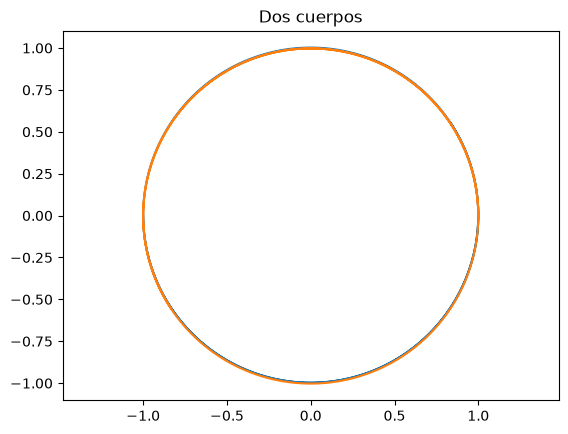

In [1]:
import matplotlib.pyplot as plt

def simula(cuerpos, pasos, dt=0.01, G=1.0):
    trayectorias = [[(c["x"], c["y"])] for c in cuerpos]
    try:
        for _ in range(pasos):
            for i, a in enumerate(cuerpos):
                ax = ay = 0.0
                for j, b in enumerate(cuerpos):
                    if i == j:
                        continue
                    dx, dy = b["x"] - a["x"], b["y"] - a["y"]
                    r2 = dx * dx + dy * dy
                    if r2 == 0:
                        # misma posición: termina la simulación
                        return trayectorias
                    f = G * b["m"] / r2**1.5
                    ax, ay = ax + f * dx, ay + f * dy
                a["vx"] += ax * dt
                a["vy"] += ay * dt
            for c, t in zip(cuerpos, trayectorias):
                c["x"] += c["vx"] * dt
                c["y"] += c["vy"] * dt
                t.append((c["x"], c["y"]))
    except KeyboardInterrupt:
        pass
    return trayectorias

dos = [dict(x=-1, y=0, vx=0, vy=-0.5, m=1), dict(x=1, y=0, vx=0, vy=0.5, m=1)]
print(len(simula([dict(x=0, y=0, vx=0, vy=0, m=1), dict(x=0, y=0, vx=0, vy=0, m=1)], 10)[0]), "posición: terminó sin error")
for t in simula(dos, 2000):
    plt.plot(*zip(*t))
plt.axis("equal")
plt.title("Dos cuerpos")
plt.show()

## 2. Tres cuerpos

Extender la simulación a tres cuerpos: cada cuerpo recibe la suma de las fuerzas de los demás (la función anterior ya lo admite).

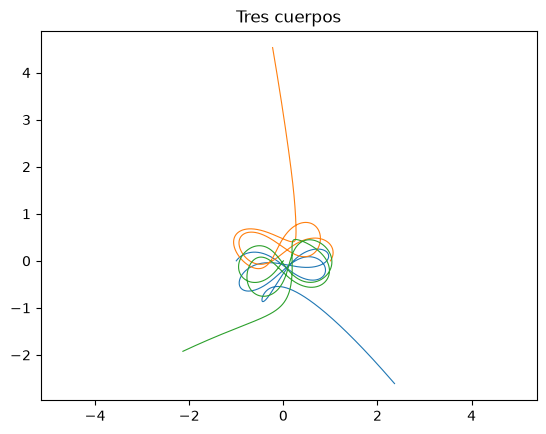

In [2]:
tres = [dict(x=-1, y=0, vx=0.35, vy=0.5, m=1), dict(x=1, y=0, vx=0.35, vy=0.5, m=1), dict(x=0, y=0, vx=-0.7, vy=-1, m=1)]
for t in simula(tres, 3000, dt=0.005):
    plt.plot(*zip(*t), linewidth=0.8)
plt.axis("equal")
plt.title("Tres cuerpos")
plt.show()

## 3. Alunizaje

Simular una nave que cae por la gravedad y usa un propulsor que gasta combustible. Variantes: barra de combustible roja por debajo del 25 %; niveles fácil, normal y difícil (combustible, consumo y gravedad); plataforma flotante a la que hay que llegar desde arriba; fondo negro con estrellas y llamas del propulsor; y meteoritos que destruyen la nave al tocarla.

fácil    -> aterrizaje correcto, combustible restante 192.0
normal   -> aterrizaje correcto, combustible restante 95.0
difícil  -> aterrizaje correcto, combustible restante 16.0


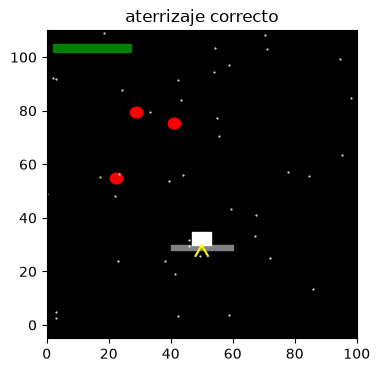

In [3]:
import random
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle

NIVELES = {"fácil": (200, 0.5, 0.05), "normal": (120, 1.0, 0.08), "difícil": (70, 1.5, 0.12)}

def alunizaje(nivel="normal", plataforma_y=0.0, meteoritos=3, semilla=1):
    random.seed(semilla)
    fuel_max, consumo, gravedad = NIVELES[nivel]
    fuel, y, vy, x = fuel_max, 100.0, 0.0, 50.0
    rocas = [[random.uniform(0, 100), random.uniform(20, 90), random.uniform(-0.5, 0.5)] for _ in range(meteoritos)]
    historia, estado = [], "en vuelo"
    while estado == "en vuelo":
        # piloto: frena si va rápido cerca de la plataforma
        propulsor = fuel > 0 and vy < -1.0 - (y - plataforma_y) / 60
        if propulsor:
            vy += 0.2
            fuel -= consumo
        vy -= gravedad
        y += vy
        for r in rocas:
            r[0] = (r[0] + r[2]) % 100
            if (r[0] - x) ** 2 + (r[1] - y) ** 2 < 9:
                estado = "destruida por un meteorito"
        historia.append((y, fuel, propulsor))
        if y <= plataforma_y and estado == "en vuelo":
            estado = "aterrizaje correcto" if vy > -2 else "estrellada"
    return historia, rocas, estado, fuel_max

def dibuja(historia, rocas, estado, fuel_max, plataforma_y=0.0):
    y, fuel, propulsor = historia[-1]
    fig, ax = plt.subplots(figsize=(4, 4))
    ax.set_facecolor("black")
    for _ in range(40):
        ax.plot(random.uniform(0, 100), random.uniform(0, 110), "w.", markersize=1)
    ax.add_patch(Rectangle((40, plataforma_y - 2), 20, 2, color="grey"))
    ax.add_patch(Rectangle((47, y), 6, 5, color="white"))
    if propulsor:
        ax.plot([48, 50, 52], [y - 4, y, y - 4], color="yellow")
    for r in rocas:
        ax.add_patch(Circle((r[0], r[1]), 2, color="red"))
    ax.add_patch(Rectangle((2, 102), 30 * max(fuel, 0) / fuel_max, 3, color="red" if fuel < fuel_max / 4 else "green"))
    ax.set(xlim=(0, 100), ylim=(-5, 110), title=estado)
    plt.show()

for nivel in NIVELES:
    historia, rocas, estado, fuel_max = alunizaje(nivel, meteoritos=0)
    print(f"{nivel:8} -> {estado}, combustible restante {historia[-1][1]:.1f}")
historia, rocas, estado, fuel_max = alunizaje("normal", plataforma_y=30, meteoritos=3)
dibuja(historia, rocas, estado, fuel_max, plataforma_y=30)

## 4. Frontón y teletenis

Una pelota rebota en las paredes y el jugador mueve una raqueta en el borde inferior; si la pelota sale por abajo, termina. En el teletenis, el ordenador controla otra raqueta arriba sin moverse más rápido que el jugador.

In [4]:
def partida(teletenis=False, pasos=2000, velocidad_raqueta=1.2, ancho=40, alto=60):
    bx, by, vx, vy = 20.0, 30.0, 0.9, -1.3
    abajo = arriba = 20.0
    golpes = 0
    for paso in range(pasos):
        # el jugador sigue la pelota con velocidad limitada
        abajo += max(-velocidad_raqueta, min(velocidad_raqueta, bx - abajo))
        if teletenis:
            arriba += max(-velocidad_raqueta, min(velocidad_raqueta, bx - arriba))
        bx, by = bx + vx, by + vy
        if not 0 <= bx <= ancho:
            vx = -vx
        if by >= alto:
            if teletenis and abs(bx - arriba) > 4:
                return f"punto para el jugador en el paso {paso}", golpes
            vy = -vy
        if by <= 0:
            if abs(bx - abajo) > 4:
                return f"la pelota salió por abajo en el paso {paso}", golpes
            vy, golpes = -vy, golpes + 1
    return "fin de la simulación", golpes

print("Frontón:", partida())
print("Frontón con raqueta lenta:", partida(velocidad_raqueta=0.5))
print("Teletenis:", partida(teletenis=True))

Frontón: ('fin de la simulación', 21)
Frontón con raqueta lenta: ('la pelota salió por abajo en el paso 23', 0)
Teletenis: ('fin de la simulación', 21)
